In [1]:
import os
import sys
import numpy as np
import pandas as pd
sys.path.append("../utils")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# clean text data
import re
# import string
# from nltk.corpus import stopwords
# from nltk.stem import WordNetLemmatizer
# import nltk 

import spacy
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from wordcloud import WordCloud

# nltk.download("stopwords")
# nltk.download("wordnet")
# nltk.download("omw-1.4")


# text embeddings
from transformers import AutoTokenizer, AutoModel
from embedding_utils import extract_embeddings
from sentence_transformers import SentenceTransformer


# clustering
import hdbscan
from bertopic import BERTopic

# visualization
import matplotlib.pyplot as plt


/Users/jasperhoong/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("../data/raw/corrected_data.csv")
df.head()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,NaN,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,NaN,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../downloaded_legislation/state/MA/192nd/2025/...
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,NaN,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,Department of Veterans’ Services,NaN,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,NaN,https://malegislature.gov/Bills/192/SD3464.pdf,False,NaN,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,NaN,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...


In [3]:
display(df.head())
print(df.shape)
df.info()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,NaN,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,NaN,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../downloaded_legislation/state/MA/192nd/2025/...
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,NaN,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,Department of Veterans’ Services,NaN,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,NaN,https://malegislature.gov/Bills/192/SD3464.pdf,False,NaN,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,NaN,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...


(67153, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67153 entries, 0 to 67152
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   bill_number       67153 non-null  object
 1   bill_url          67153 non-null  object
 2   bill_title        67153 non-null  object
 3   sponsor_name      67153 non-null  object
 4   sponsor_url       45765 non-null  object
 5   summary_title     67153 non-null  object
 6   summary_text      64398 non-null  object
 7   source_url        67153 non-null  object
 8   view_text_url     60063 non-null  object
 9   download_pdf_url  67153 non-null  object
 10  is_home_rule      67153 non-null  bool  
 11  municipality      3957 non-null   object
 12  num_cosponsors    67153 non-null  int64 
 13  cosponsors        67153 non-null  object
 14  history           66923 non-null  object
 15  path              67153 non-null  object
dtypes: bool(1), int64(1), object(14)
memory usage:

In [4]:
# PROBLEM 1
# Summary texts are not unique!
# SOME TExts can be replaced with nan val
df.summary_text.value_counts()

summary_text
Text is available in House Clerk's office ...                                                                                                                                                    529
Text is available in the House Clerk's Office ...                                                                                                                                                224
Ordered, That the committee on Environment, Natural Resources and Agriculture be authorized to sit during a recess of the General Court to make an investigation and study of House ...           49
SECTION 1. Notwithstanding sections 32 to 37, inclusive, of chapter 7C of the General Laws or any other general or special law to the contrary, the commissioner of capital asset ...             46
Ordered, That the committee on State Administration and Regulatory Oversight be authorized to sit during a recess of the General Court to make an investigation and study of House ...            35
  

In [5]:
df.summary_text.value_counts()[:30]

summary_text
Text is available in House Clerk's office ...                                                                                                                                              529
Text is available in the House Clerk's Office ...                                                                                                                                          224
Ordered, That the committee on Environment, Natural Resources and Agriculture be authorized to sit during a recess of the General Court to make an investigation and study of House ...     49
SECTION 1. Notwithstanding sections 32 to 37, inclusive, of chapter 7C of the General Laws or any other general or special law to the contrary, the commissioner of capital asset ...       46
Ordered, That the committee on State Administration and Regulatory Oversight be authorized to sit during a recess of the General Court to make an investigation and study of House ...      35
Report of the Executive Office o

In [6]:
placeholder_phrases = [
    "Text is available in the House Clerk's Office",
    "Text is available in House Clerk's office",
    "Text is available in the office of the Clerk of the House ... ",
    "Text is available in the office of the House Clerk ..."

    "",
    "5"
]

df['summary_text_clean'] = df['summary_text'].apply(
    lambda x: np.nan if any(phrase.lower() in str(x).lower() for phrase in placeholder_phrases) else x

)

In [7]:
df.summary_text_clean.value_counts()

summary_text_clean
Ordered, That the committee on Environment, Natural Resources and Agriculture be authorized to sit during a recess of the General Court to make an investigation and study of House ...    49
SECTION 1. Notwithstanding sections 32 to 37, inclusive, of chapter 7C of the General Laws or any other general or special law to the contrary, the commissioner of capital asset ...      46
Ordered, That the committee on State Administration and Regulatory Oversight be authorized to sit during a recess of the General Court to make an investigation and study of House ...     35
Ordered, That the committee on Children, Families and Persons with Disabilities be authorized to sit during a recess of the General Court to make an investigation and study of ...        23
SECTION 1. (a) Notwithstanding sections 32 to 37, inclusive, of chapter 7C of the General Laws or any other general or special law to the contrary, the commissioner of capital ...        23
                               

In [8]:
df['summary_title_clean'] = df['summary_title'].apply(
    lambda x: np.nan if any(phrase.lower() in str(x).lower() for phrase in placeholder_phrases) else x

)
df.summary_title_clean.value_counts()[:30]

summary_title_clean
Study Order                                                                                                                                                 305
Extension Order - Public Service                                                                                                                             45
Extension Order - Transportation                                                                                                                             38
Extension Order - Labor and Workforce Development                                                                                                            33
An Act financing improvements to municipal roads and bridges                                                                                                 32
An Act concerning the safety of school children embarking and disembarking school buses                                                                      31
Extension Order - Re

NOTE: Many bills may have duplicate titles but can be different/separate bills, when working on the full data ensure to not drop duplicate bill titles

In [9]:
# Drop NaNs and duplicates
df_topic = df.dropna(subset=['summary_title_clean']).drop_duplicates(subset=['summary_title_clean'])
len(df_topic)

36304

In [10]:
df_topic["summary_title_clean"].isna().sum( )

0

In [11]:
# Load spaCy English model with NER and parser disabled for speed
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

custom_stopwords = set([
    "section", "chapter", "general", "laws", "hereby", "amended", "insert", "enact",
    "enactment", "law", "legislation", "act", "resolve", "order", "committee", "bill",
    "house", "senate", "commonwealth", "public", "private", "regulation", "statute",
    "effective", "provision", "subsection", "notwithstanding", "pursuant", "authorized",
    "office", "duty", "power", "authority", "text", "available", "clerk", "authorized",
    "recess", "investigation", "study", "authorized", "sitting", "office", "provide",
    "shall",  "state", "amend", "official", "edition", 
    "insert", "follow", "paragraph", "clause", "department", "relative",
    "massachusetts", "submit", "", "establish",
        "leave",     # very common, ambiguous
    "sick",      # procedural in employee/sick leave laws
    "bank",      # often just "sick leave bank"
    "employee",  # generic term across labor bills
    "fiscal",    # procedural, not topically defining
    "fund",      # generic
    "year",      # always present in budget/timing
    "commission",# too procedural, like “committee”
    "inspection",# structural
    "service",   # too vague
    "item",      # budget structure
    "county",    # geographical, not thematic
    "trust"      # legal term, often in estate/tax docs
])
stopwords = ENGLISH_STOP_WORDS.union(custom_stopwords)


In [12]:
def preprocess(text):
    if pd.isnull(text):
        return ""
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if token.is_alpha and not token.is_stop and token.lemma_ not in stopwords
    ]
    return " ".join(tokens)

# Apply preprocessing
df_topic["cleaned"] = df_topic["summary_title_clean"].apply(preprocess)


In [13]:
df_topic[['summary_title', 'cleaned']].head(10)

,summary_title,cleaned
0,An Act providing technical education and econo...,technical education economic opportunity citiz...
1,An Act relative to recovery homes,recovery home
2,An Act amending the Medal of Liberty,medal liberty
3,DVS Veteran Advisory Committee Interim Report,dvs veteran advisory interim report
4,An Act to encourage Massachusetts residency,encourage residency
5,An Act relative to establishing institutional ...,institutional partnership
6,An Act exempting zero-emission commercial vehi...,exempt zero emission commercial vehicle sale tax
7,An Act to expand membership opportunities in l...,expand membership opportunity local cultural c...
8,Resolve establishing a task force to study rac...,task force racial disparity home ownership red...
9,An Act to prevent the illegal possession and i...,prevent illegal possession illegal sale firearm


In [14]:
df_topic.shape

(36304, 19)

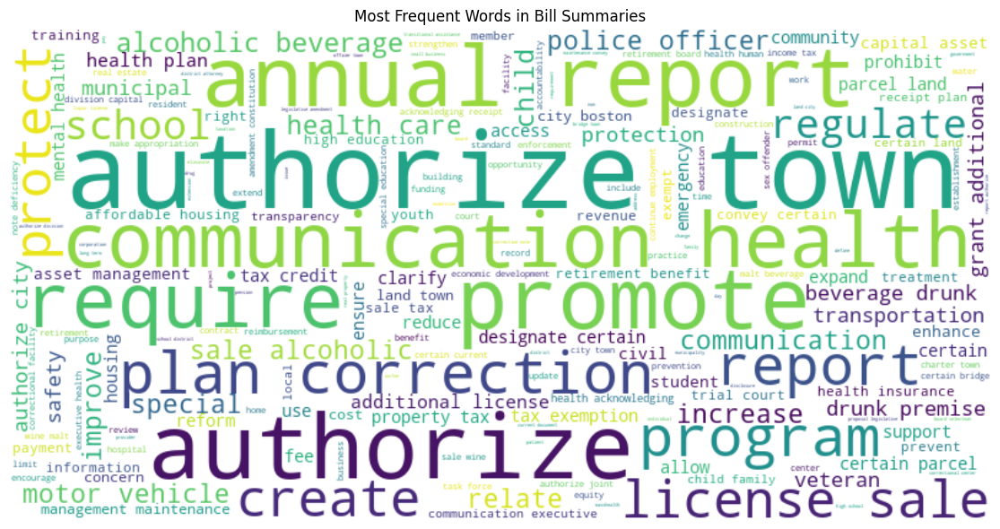

In [15]:
# Combine all bill summaries into one string
text_data = " ".join(df_topic['cleaned'].dropna()).lower()

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    # stopwords=stop_words,
    # max_words=100
).generate(text_data)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequent Words in Bill Summaries")
plt.tight_layout()
plt.show()


### BERTopic

In [16]:
df_topic.head()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path,summary_text_clean,summary_title_clean,cleaned
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,NaN,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,"(a) For purposes of this act, “autism spectrum...",An Act providing technical education and econo...,technical education economic opportunity citiz...
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,NaN,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../downloaded_legislation/state/MA/192nd/2025/...,Nothwithstanding any special or general law to...,An Act relative to recovery homes,recovery home
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,NaN,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,NaN,An Act amending the Medal of Liberty,medal liberty
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,Department of Veterans’ Services,NaN,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,NaN,https://malegislature.gov/Bills/192/SD3464.pdf,False,NaN,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,Report of the Department of Veterans’ Services...,DVS Veteran Advisory Committee Interim Report,dvs veteran advisory interim report
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,NaN,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,NaN,An Act to encourage Massachusetts residency,encourage residency


In [26]:
texts = df_topic['cleaned']

In [18]:
from sentence_transformers import SentenceTransformer

# Load Legal-BERT model (HuggingFace name is correct here)
embedding_model = SentenceTransformer("nlpaueb/legal-bert-base-uncased")
topic_model = BERTopic(embedding_model=embedding_model)

topics, probs = topic_model.fit_transform(texts)
topic_model.visualize_topics()

No sentence-transformers model found with name nlpaueb/legal-bert-base-uncased. Creating a new one with mean pooling.


In [32]:
topic_model.reduce_topics(texts, nr_topics=50)
new_topics, new_probs = topic_model.fit_transform(texts)

In [34]:
topic_model.visualize_barchart()

In [35]:
print(new_topics)
print(new_probs)
print(texts)

[0, -1, -1, -1, -1, -1, -1, -1, -1, -1, 0, 0, 0, 1, -1, 0, 10, 0, -1, 1, 8, -1, -1, -1, -1, -1, -1, -1, 0, -1, 0, -1, 29, -1, 3, -1, 0, 0, -1, -1, -1, 0, 0, 0, 0, -1, -1, 0, 0, -1, 2, 0, -1, -1, -1, -1, 1, 2, 4, -1, -1, 0, 1, -1, -1, -1, 1, 0, 0, 0, 3, 0, 1, -1, -1, -1, 24, -1, -1, 0, 0, 0, 0, -1, 0, 1, 0, 0, 1, 1, 1, 2, 2, 8, -1, -1, 0, -1, -1, -1, -1, 0, 9, 0, -1, -1, 5, -1, -1, 0, -1, -1, -1, 0, -1, 23, -1, 0, 0, 27, -1, -1, 0, -1, 11, -1, 2, 0, 0, -1, -1, 2, 0, -1, 5, 0, -1, 4, -1, 3, 0, 0, 8, -1, -1, -1, -1, 0, -1, -1, 0, 0, 0, -1, -1, 0, -1, -1, -1, -1, -1, -1, 33, 0, 0, -1, -1, 0, 1, 0, -1, 0, -1, 1, -1, 0, 0, 6, -1, 0, 0, 2, -1, -1, 0, 2, 5, 0, 1, 0, 0, 0, -1, -1, 0, -1, -1, 0, 0, -1, 2, 0, 1, 1, 0, 0, 0, 0, 2, -1, -1, 0, 1, 1, -1, -1, 13, 0, 0, -1, 0, -1, -1, 7, -1, -1, 0, 1, 0, -1, -1, 0, -1, 0, 0, 5, -1, 1, -1, 12, -1, 42, -1, 0, -1, -1, 0, 1, 0, 0, -1, 0, 0, -1, 0, -1, -1, 4, -1, 2, -1, 0, -1, 4, -1, -1, 1, -1, 3, -1, 0, 0, 3, 0, -1, 8, 0, 0, -1, 6, 2, 0, -1, -1, -1, -1, 5,

In [36]:
df_topic["topic"] = new_topics 
df_topic["topic_probability"] = new_probs

In [37]:
df_topic = df_topic.rename(columns={"bill_title": "title", "summary_text": "text", "sponsor_name": "sponsor"})
df_topic[df_topic['municipality'] == "Boston"]

,bill_number,bill_url,title,sponsor,sponsor_url,summary_title,text,source_url,view_text_url,download_pdf_url,...,municipality,num_cosponsors,cosponsors,history,path,summary_text_clean,summary_title_clean,cleaned,topic,topic_probability
125,H.5097,https://malegislature.gov/Bills/192/H5097,An Act relative to certain affordable housing ...,"Michlewitz, Aaron",https://malegislature.gov/Legislators/Profile/...,An Act relative to certain affordable housing ...,SECTION 1. Construction and development activi...,https://malegislature.gov/Bills/192/H5097,https://malegislature.gov/Bills/192/H5097/Hous...,https://malegislature.gov/Bills/192/H5097.pdf,...,Boston,0,[],"[{'date': '7/26/2022', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,SECTION 1. Construction and development activi...,An Act relative to certain affordable housing ...,certain affordable housing branch library spac...,0,0.438492
294,H.5039,https://malegislature.gov/Bills/192/H5039,An Act relative to Chapter 30B: Uniform Procur...,"Holmes, Russell E.",https://malegislature.gov/Legislators/Profile/...,An Act relative to Chapter 30B: Uniform Procur...,"In the City of Boston, notwithstanding section...",https://malegislature.gov/Bills/192/H5039,https://malegislature.gov/Bills/192/H5039/Hous...,https://malegislature.gov/Bills/192/H5039.pdf,...,Boston,0,[],"[{'date': '7/18/2022', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,NaN,An Act relative to Chapter 30B: Uniform Procur...,uniform procurement,3,1.000000
567,H.3753,https://malegislature.gov/Bills/192/H3753,An Act regarding preference for Boston high sc...,"Fluker Oakley, Brandy",https://malegislature.gov/Legislators/Profile/...,An Act regarding preference for Boston high sc...,"SECTION 1. In this act, all terms shall have t...",https://malegislature.gov/Bills/192/H3753,https://malegislature.gov/Bills/192/H3753/Hous...,https://malegislature.gov/Bills/192/H3753.pdf,...,Boston,0,[],"[{'date': '5/10/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,"SECTION 1. In this act, all terms shall have t...",An Act regarding preference for Boston high sc...,preference boston high school graduate positio...,-1,0.000000
1058,H.5330,https://malegislature.gov/Bills/192/H5330,An Act regarding the disability pension for El...,"Hunt, Daniel J.",https://malegislature.gov/Legislators/Profile/...,An Act regarding the disability pension for El...,Section 1. (a) Notwithstanding any general or ...,https://malegislature.gov/Bills/192/H5330,https://malegislature.gov/Bills/192/H5330/Hous...,https://malegislature.gov/Bills/192/H5330.pdf,...,Boston,0,[],"[{'date': '9/29/2022', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,Section 1. (a) Notwithstanding any general or ...,An Act regarding the disability pension for El...,disability pension elaina mcalister,0,0.502576
2347,H.4111,https://malegislature.gov/Bills/192/H4111,An Act authorizing the city of Boston to estab...,"Miranda, Liz",https://malegislature.gov/Legislators/Profile/...,An Act authorizing the city of Boston to estab...,Section 1. Paragraph (i) of subdivision (4) of...,https://malegislature.gov/Bills/192/H4111,https://malegislature.gov/Bills/192/H4111/Hous...,https://malegislature.gov/Bills/192/H4111.pdf,...,Boston,16,"[{'name': 'Thomas M. Stanley', 'district': '9t...","[{'date': '9/16/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...,NaN,An Act authorizing the city of Boston to estab...,authorize city boston alternative superannuati...,-1,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61255,H.3759,https://malegislature.gov/Bills/190/H3759,An Act relative to expanding access to high qu...,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to expanding access to high qu...,SECTION 1. Section 10 of chapter 152 of the ac...,https://malegislature.gov/Bills/1

In [39]:
df_topic.to_csv('../data/raw/boston_topic_bill_data.csv', index=False, quotechar='"', quoting=2, encoding='utf-8')